# Знако-ранговая карта Шухарта (Shewhart Signed-Rank Chart)

**Непараметрическая карта для медианы непрерывного симметричного
распределения.** Использует и знаки, и ранги отклонений от $\mu_0$, поэтому
мощнее знаковой карты, но требует симметрии.

Источник: Chakraborti & Graham (2019), § 4.2.1.2.1 «A Shewhart Signed-rank
Chart», стр. 197–202; выбор константы $a$ — стр. 198.

> Ноутбук запускается из каталога `notebooks/`. Численные примеры книги
> (4.4–4.5) сверяются автотестами `tests/` и `examples/`.

## 1. Импорты и настройка

In [1]:
import sys
sys.path.append('../src')      # запуск из каталога notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from nonparametric_charts.utils import (
    ACCENT,
    VIOLATION,
    WARNING,
    DataLoader,
    DataPreprocessor,
    apply_minimal_latex_style,
    find_iqr_outliers,
    iqr_fences,
    winsorize_outliers,
    summarize_dataset,
)
from nonparametric_charts.charts import (
    CusumSignChart,
    CusumSignedRankChart,
    SignChart,
    SignedRankChart,
)

apply_minimal_latex_style()

## 2. Теория (минимум)

**Постановка (Case K).** Независимые подгруппы $X_{{i1}},\ldots,X_{{in}}$,
распределение $F$ непрерывно и **симметрично** относительно центра $\mu$,
целевое значение $\mu_0$ известно. Симметрия — обязательное условие: без неё
распределение статистики зависит от $F$.

**Статистика подгруппы** (ур. 4.4–4.5, стр. 197):

$$SR_i=\sum_{j=1}^{n}\operatorname{sign}(X_{ij}-\mu_0)\,R_{ij}
=2T_i^{+}-S,\qquad S=\frac{n(n+1)}{2},$$

где $R_{ij}$ — ранг $|X_{ij}-\mu_0|$ внутри подгруппы, $T_i^{+}$ — статистика
знаковых рангов Уилкоксона. В IC $E(SR_i)=0$,
$SD(SR_i)=\sqrt{n(n+1)(2n+1)/6}$.

**Границы и сигнал** (ур. 4.6, стр. 198):

$$UCL=+a,\qquad CL=0,\qquad LCL=-a;\qquad \text{сигнал при } |SR_i|\ge a.$$

**Выбор $a$** (стр. 198): наименьшее целое с
$P_{\mu_0}(SR_i\ge a)\le FAR_0/2$.

In [2]:
# Те же формулы в виде кода (реализация — в пакете nonparametric_charts):
# SR_i = Σ sign(X_ij − μ0)·R_ij = 2·T_i+ − S,   S = n(n+1)/2
# R_ij — ранг |X_ij − μ0| внутри подгруппы (совпадения — средний ранг)
# UCL = +a, CL = 0, LCL = −a;  сигнал при |SR_i| >= a
# a — наименьшее целое с P(SR >= a) <= FAR0/2   (§ 4.2.1.2.1, стр. 198)

## 3. Загрузка `data.csv`

Строка = подгруппа, столбец = наблюдение; `n` — число столбцов. Целевое
значение $\mu_0$ фиксируем по медиане исходных данных, чтобы оба прохода
сравнивались при одном центре.

In [3]:
DATA_PATH = '../data/data.csv'

raw = DataLoader(DATA_PATH).load()
preprocessor = DataPreprocessor(raw)
data, n = preprocessor.get_data_for_chart()

# Целевое значение фиксируем по исходным данным, чтобы оба прохода
# (исходные и очищенные данные) сравнивались при одном μ₀.
MU0 = round(float(np.nanmedian(data.to_numpy(dtype=float))), 3)
FAR0 = 0.0027

print(f'Подгрупп: {len(data)}; наблюдений в подгруппе: n = {n}')
print(f'Целевое значение μ₀ = {MU0:g}; номинальный FAR₀ = {FAR0}')
display(data)

Подгрупп: 10; наблюдений в подгруппе: n = 14
Целевое значение μ₀ = 0.323; номинальный FAR₀ = 0.0027


,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,x11,x12,x13,x14
0,0.152,0.383,0.094,0.067,0.00001,0.316,0.3372,0.811,0.038,0.701,0.137,0.159,0.4571,0.2809
1,0.116,-1.647,0.098,0.642,0.79100,0.988,-0.1760,0.968,0.385,0.361,0.167,0.435,0.9870,0.9940
2,0.322,0.962,0.533,0.798,0.40100,0.838,0.1820,0.632,0.265,0.170,0.783,0.324,0.7710,0.0001
3,0.351,0.829,0.298,-1.892,0.95500,0.688,0.9880,0.477,0.301,0.291,0.565,0.995,0.8890,1.0290
4,0.279,0.003,0.168,22.437,0.87600,-0.127,-0.1370,0.240,0.190,0.289,0.335,0.764,0.2930,0.1120
5,0.239,0.601,0.226,0.986,0.40100,0.158,0.6090,0.093,1.055,0.242,0.251,0.965,0.4920,0.1320
6,0.983,0.785,1.141,4.593,0.45300,0.199,0.5820,0.148,0.402,0.253,0.273,0.381,0.5130,0.3220
7,0.415,0.061,1.823,0.814,0.45100,-0.029,0.7420,0.246,0.332,0.244,0.186,0.944,0.5300,0.3070
8,0.324,0.048,-1.152,-0.072,0.34700,0.714,0.7030,0.226,0.032,0.106,0.164,0.375,0.3070,0.3360
9,0.090,0.168,1.306,0.042,0.28300,0.347,0.5870,0.264,0.029,0.046,0.207,0.153,0.0470,0.1510


## 4. Проверка данных

Кроме пропусков и выбросов для SR-карты обязательна проверка **симметрии**:
сравниваем среднее с медианой и смотрим асимметрию. Выбросы ищутся по
правилу Тьюки.

In [4]:
summary = summarize_dataset(data)
display(summary.to_frame())

print('Описательные статистики по столбцам:')
display(data.describe().round(3).T)

,значение
подгрупп,10.000000
наблюдений в подгруппе (n),14.000000
ячеек всего,140.000000
пропусков,0.000000
минимум,-1.892000
Q1,0.162750
медиана,0.323000
Q3,0.691250
максимум,22.437000
среднее,0.565938


Описательные статистики по столбцам:


,count,mean,std,min,25%,50%,75%,max
x1,10.0,0.327,0.254,0.090,0.174,0.300,0.344,0.983
x2,10.0,0.219,0.746,-1.647,0.051,0.276,0.739,0.962
x3,10.0,0.454,0.821,-1.152,0.116,0.262,0.989,1.823
x4,10.0,2.842,7.071,-1.892,0.048,0.720,0.943,22.437
x5,10.0,0.496,0.294,0.000,0.360,0.426,0.706,0.955
x6,10.0,0.409,0.378,-0.127,0.168,0.332,0.708,0.988
x7,10.0,0.442,0.383,-0.176,0.221,0.584,0.680,0.988
x8,10.0,0.410,0.299,0.093,0.230,0.255,0.593,0.968
x9,10.0,0.303,0.301,0.029,0.076,0.283,0.372,1.055
x10,10.0,0.270,0.178,0.046,0.188,0.248,0.290,0.701


In [5]:
print(f"Асимметрия: {summary['асимметрия']:.3f}")
print(f"Среднее − медиана: {summary['среднее'] - summary['медиана']:.3f}")
print('Для SR-карты требуется симметрия (стр. 197–198).')

Асимметрия: 10.366
Среднее − медиана: 0.243
Для SR-карты требуется симметрия (стр. 197–198).


In [6]:
outliers = find_iqr_outliers(data)
lower, upper, q1, q3 = iqr_fences(data.to_numpy(dtype=float))

print(f'Квартили: Q1 = {q1:.3f}, Q3 = {q3:.3f}')
print(f'IQR-забор: [{lower:.3f}; {upper:.3f}]')
print(f'Выбросов: {len(outliers)} из {data.size} ячеек')
display(outliers)

Квартили: Q1 = 0.163, Q3 = 0.691
IQR-забор: [-0.630; 1.484]
Выбросов: 6 из 140 ячеек


,subgroup,column,value,lower,upper
0,2,x2,-1.647,-0.63,1.484
1,4,x4,-1.892,-0.63,1.484
2,5,x4,22.437,-0.63,1.484
3,7,x4,4.593,-0.63,1.484
4,8,x3,1.823,-0.63,1.484
5,9,x3,-1.152,-0.63,1.484


**Что видно.** Пропусков нет. Асимметрия $10.37$, среднее заметно больше
медианы — распределение сильно скошено вправо, формально условие симметрии
не выполнено. Причина — шесть выбросов (до $22.437$). Ниже строим карту на
исходных данных как учебный пример, но выводы по ней делать нельзя; затем
повторяем анализ после замены выбросов.

## 5. Графики данных

In [7]:
def plot_data_overview(frame, title):
    """Гистограмма значений и ящики по подгруппам — проверка данных."""
    values = frame.to_numpy(dtype=float).ravel()
    values = values[~np.isnan(values)]
    found = find_iqr_outliers(frame)
    lower, upper, _, _ = iqr_fences(values)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    axes[0].hist(values, bins=15, color=ACCENT, alpha=0.75,
                 edgecolor='white')
    axes[0].axvline(MU0, color=VIOLATION, linestyle='--',
                    label=r'$\mu_0$')
    axes[0].axvline(lower, color=WARNING, linestyle=':', label='забор IQR')
    axes[0].axvline(upper, color=WARNING, linestyle=':')
    if len(found):
        axes[0].scatter(
            found['value'],
            np.full(len(found), axes[0].get_ylim()[1] * 0.06),
            color=VIOLATION, zorder=5, label='выбросы',
        )
    axes[0].set_xlabel('Значение')
    axes[0].set_ylabel('Частота')
    axes[0].set_title('Распределение всех наблюдений')
    axes[0].legend()

    axes[1].boxplot(
        [frame.iloc[i].dropna().to_numpy(dtype=float)
         for i in range(len(frame))],
        tick_labels=[str(i + 1) for i in range(len(frame))],
        medianprops={'color': ACCENT},
    )
    axes[1].axhline(MU0, color=VIOLATION, linestyle='--')
    axes[1].set_xlabel('Номер подгруппы')
    axes[1].set_ylabel('Значение')
    axes[1].set_title('Подгруппы')

    fig.suptitle(title)
    plt.tight_layout()
    return fig, axes

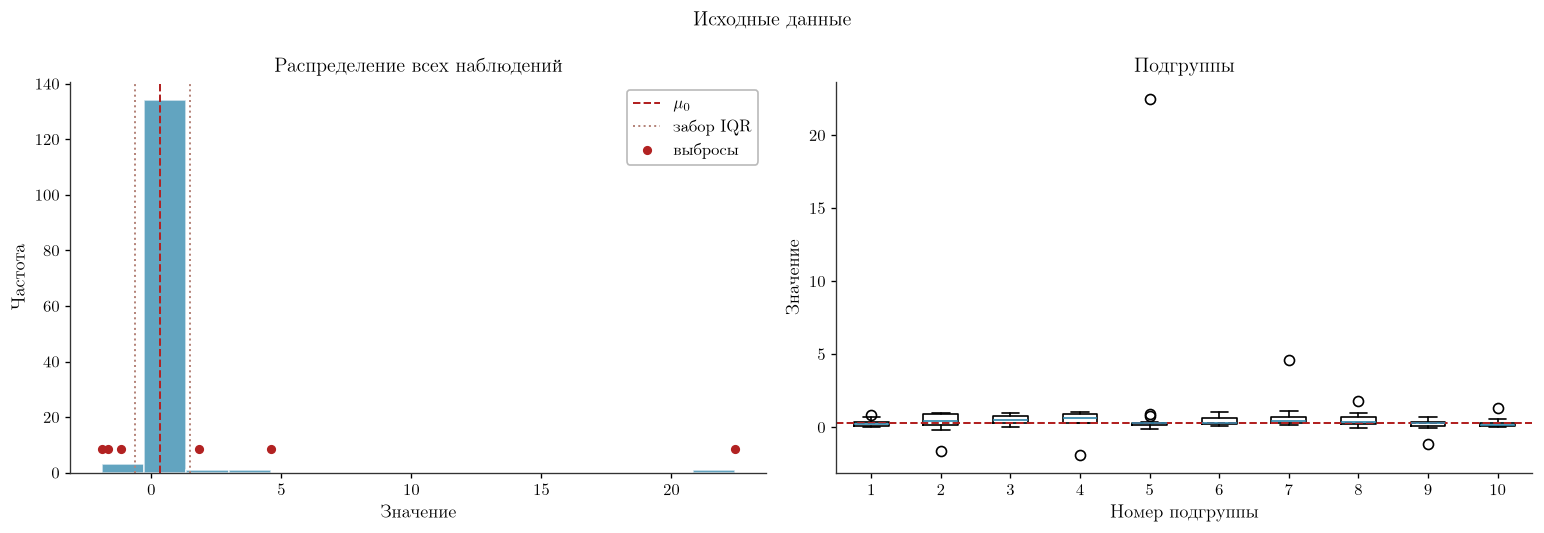

In [8]:
fig, axes = plot_data_overview(data, 'Исходные данные')
plt.show()

**Комментарий.** Гистограмма подтверждает правый хвост: масса значений
сосредоточена около $0.3$, а несколько точек уходят за $1.5$ и выше. На
ящиках видно, какие подгруппы дают выбросы (`x2`, `x3`, `x4`). Для SR-карты
важен не только центр, но и форма: тяжёлый хвост делает ранги
неинформативными — большие отклонения получают те же старшие ранги, что и
умеренные.

## 6. Подбор параметров разными методами

### 6.1. Методы подбора

Три подхода к выбору константы `a` различаются **правилом**, а не данными:

| Метод | Правило | Гарантия |
|---|---|---|
| `exact` | наименьшее `a` с $P(SR \ge a) \le FAR_0/2$ | достигнутый $FAR \le FAR_0$ |
| `nearest` | минимум $|P(|SR| \ge a) - \alpha|$ | гарантии нет |
| `normal` | нормальная аппроксимация $z_{1-FAR_0/2}\sqrt{n}$, округлённая до решётки | достижимое `a` при номинале |

Расчёт ведёт класс карты (`compare_approaches`), поэтому в ячейках нет
собственной реализации правила.

In [9]:
probe = SignedRankChart(data, sample_size=n, target_value=MU0,
              approach='exact', far0=FAR0)
comparison = probe.compare_approaches()
display(comparison[['approach', 'label', 'a', 'FAR', 'ARL_IC', 'MRL_IC']]
        .round(6))

,approach,label,a,FAR,ARL_IC,MRL_IC
0,exact,"Точный (консервативный, FAR₀)",91,0.002319,431.157895,299
1,normal,Нормальная аппроксимация,97,0.000854,1170.285714,811
2,nearest,Ближайший (α),62,0.049438,20.227160,14


**Комментарий.** При $n=14$ и $FAR_0=0.0027$ точный подход даёт $a=91$:
достигнутый $FAR\approx 0.0023$, гарантия $FAR\le FAR_0$ выполнена.
«Ближайший» подход с $\alpha=0.05$ даёт заметно меньшее `a` и FAR около
$0.05$ — почти в 20 раз больше номинала. Для карты берём `exact`.

### 6.2. Сравнение методов

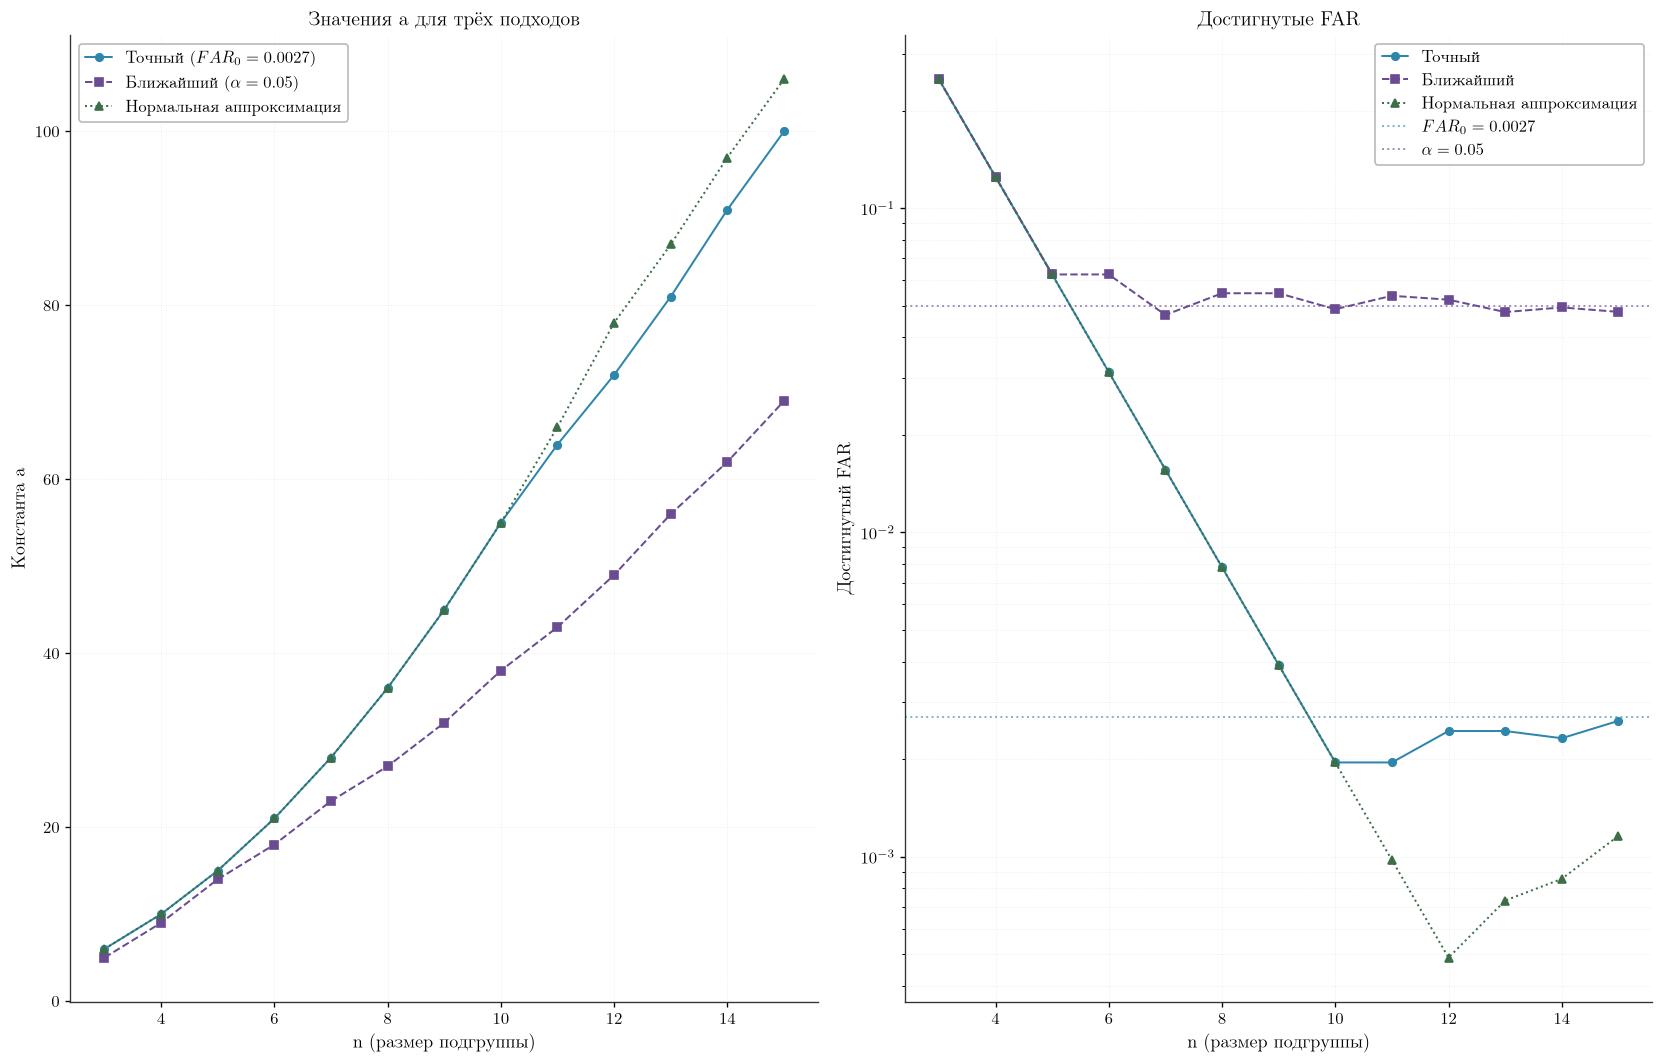

In [10]:
fig, axes = probe.plot_comparison(n_range=np.arange(3, 16))
plt.show()

**Комментарий к графику.** С ростом `n` константа `a` растёт примерно как
$\sqrt{n^3}$, а достигнутый FAR остаётся ступенчатым: при малых `n` решётка
$SR$ грубая, и номинал $0.0027$ недостижим — отсюда большие ступени на правой
панели.

## 7. Построение карты

Строим карту на исходных данных. Помним: симметрия нарушена, поэтому это
демонстрация механики, а не валидный вывод о процессе.

a = 91, LCL = -91, CL = 0, UCL = 91
Достигнутый FAR = 0.002319, ARL_IC = 431.2, MRL_IC = 299


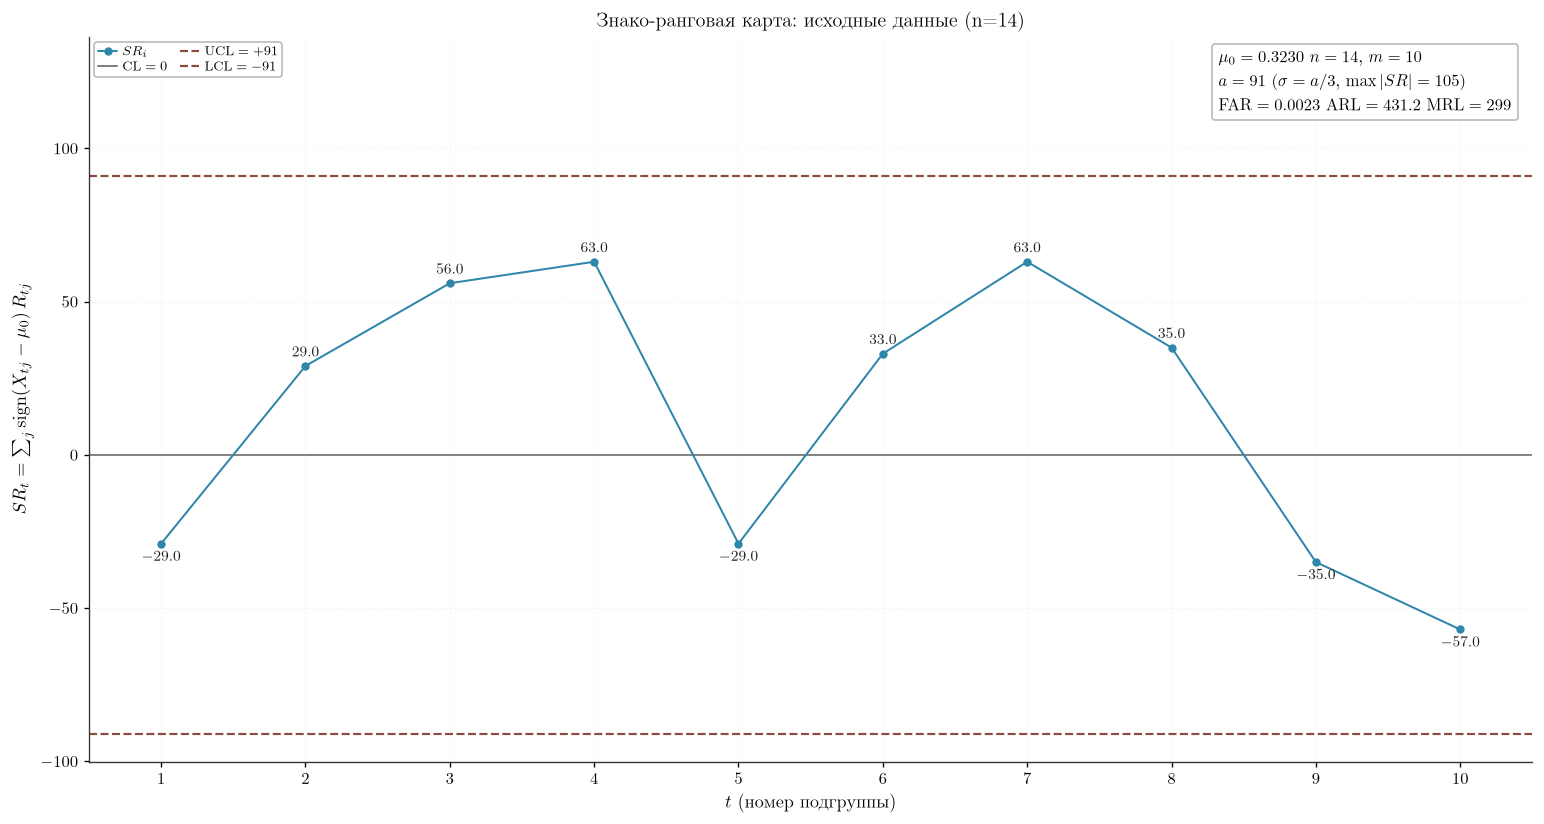

Сигналов: 0


,subgroup,value,rule


In [11]:
chart = SignedRankChart(data, sample_size=n, target_value=MU0,
                        approach='exact', far0=FAR0)
limits = chart.calculate_limits()

print(f"a = {limits['a_value']}, LCL = {limits['LCL']}, "
      f"CL = {limits['CL']}, UCL = {limits['UCL']}")
print(f"Достигнутый FAR = {limits['FAR']:.6f}, "
      f"ARL_IC = {limits['ARL_IC']:.1f}, MRL_IC = {limits['MRL_IC']}")

fig, ax = chart.plot(
    title=f'Знако-ранговая карта: исходные данные (n={n})'
)
plt.show()

violations = pd.DataFrame(chart.violations)
print(f'Сигналов: {len(violations)}')
display(violations if len(violations)
        else pd.DataFrame(columns=['subgroup', 'value', 'rule']))

**Комментарий.** Сигналов нет: даже при нарушенной симметрии $SR_i$ не
доходит до $91$. Это ожидаемо — граница $a=91$ соответствует почти всем
рангам одного знака; на 10 подгруппах такого не случилось.

## 8. Те же шаги на очищенных данных

### 8.1. Очистка выбросов

Выбросы **винзоризируем**: значения за заборами IQR заменяем самими
заборами. `n=14` и решётка статистики сохраняются, а ранги перестают
определяться одним экстремальным значением. В отличие от замены медианой,
винзоризация не переставляет наблюдение в середину подгруппы и сохраняет
порядок внутренних значений — для ранговой карты это важно.

In [12]:
data_clean, replaced = winsorize_outliers(data, outliers=outliers)

print(f'Заменено значений: {len(replaced)}; форма сохранена: '
      f'{data_clean.shape == data.shape}')
display(replaced.round(3))

Заменено значений: 6; форма сохранена: True


,subgroup,column,old_value,new_value
0,2,x2,-1.647,-0.630
1,4,x4,-1.892,-0.630
2,5,x4,22.437,1.484
3,7,x4,4.593,1.484
4,8,x3,1.823,1.484
5,9,x3,-1.152,-0.630


### 8.2. Проверка и графики

In [13]:
summary_clean = summarize_dataset(data_clean)
display(summary_clean.to_frame().rename(columns={
    'значение': 'очищенные данные'
}))

,очищенные данные
подгрупп,10.000000
наблюдений в подгруппе (n),14.000000
ячеек всего,140.000000
пропусков,0.000000
минимум,-0.630000
Q1,0.162750
медиана,0.323000
Q3,0.691250
максимум,1.484000
среднее,0.411652


In [14]:
print(f"Асимметрия после очистки: {summary_clean['асимметрия']:.3f}")
print(f"Среднее − медиана: "
      f"{summary_clean['среднее'] - summary_clean['медиана']:.3f}")

Асимметрия после очистки: 0.396
Среднее − медиана: 0.089


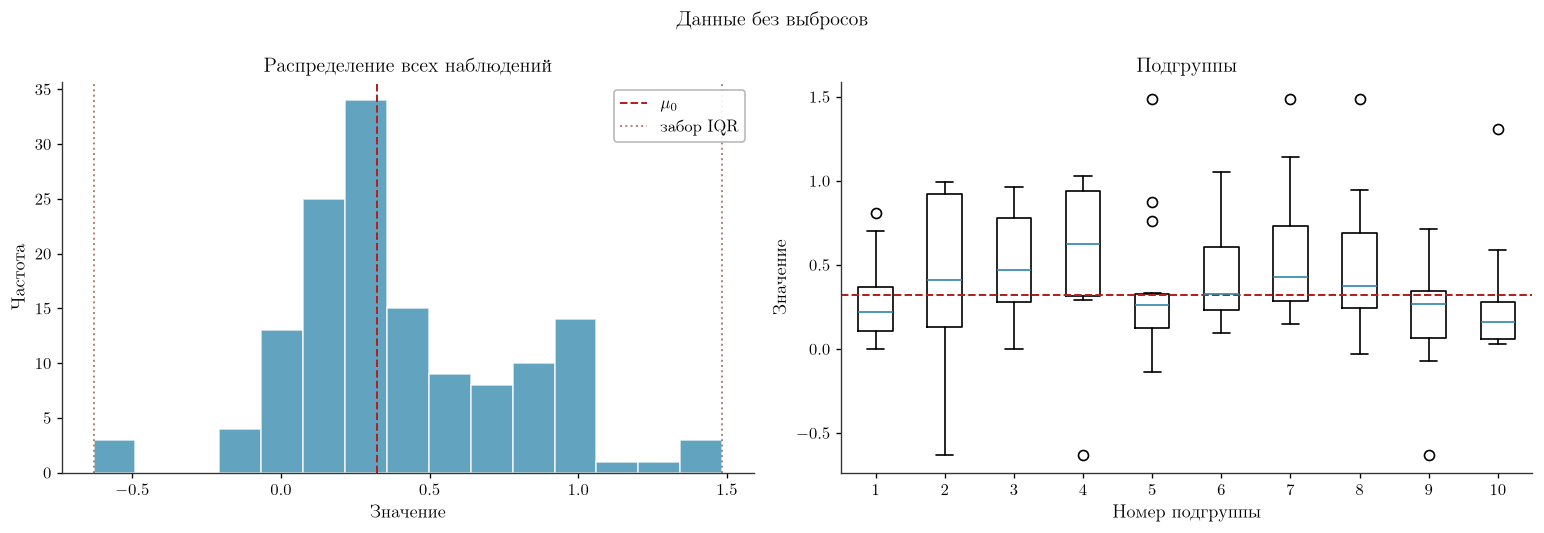

In [15]:
fig, axes = plot_data_overview(data_clean, 'Данные без выбросов')
plt.show()

**Комментарий.** Асимметрия упала с $10.37$ до $0.40$, размах — с
$[-1.89;\,22.44]$ до $[-0.63;\,1.48]$. Симметрия всё ещё приближённая
(скос $0.40$), но условие SR-карты выполняется гораздо лучше: центр и
хвосты теперь сопоставимы.

### 8.3. Подбор параметров

In [16]:
probe_clean = SignedRankChart(data_clean, sample_size=n, target_value=MU0,
                    approach='exact', far0=FAR0)
comparison_clean = probe_clean.compare_approaches()
display(comparison_clean[['approach', 'label', 'a', 'FAR', 'ARL_IC',
                          'MRL_IC']].round(6))

,approach,label,a,FAR,ARL_IC,MRL_IC
0,exact,"Точный (консервативный, FAR₀)",91,0.002319,431.157895,299
1,normal,Нормальная аппроксимация,97,0.000854,1170.285714,811
2,nearest,Ближайший (α),62,0.049438,20.227160,14


**Комментарий.** Таблица та же: `a` определяется только `n` и $FAR_0$.
Меняется лишь набор $SR_i$, поэтому переходим сразу к карте.

### 8.4. Карта на очищенных данных

a = 91, FAR = 0.002319, ARL_IC = 431.2


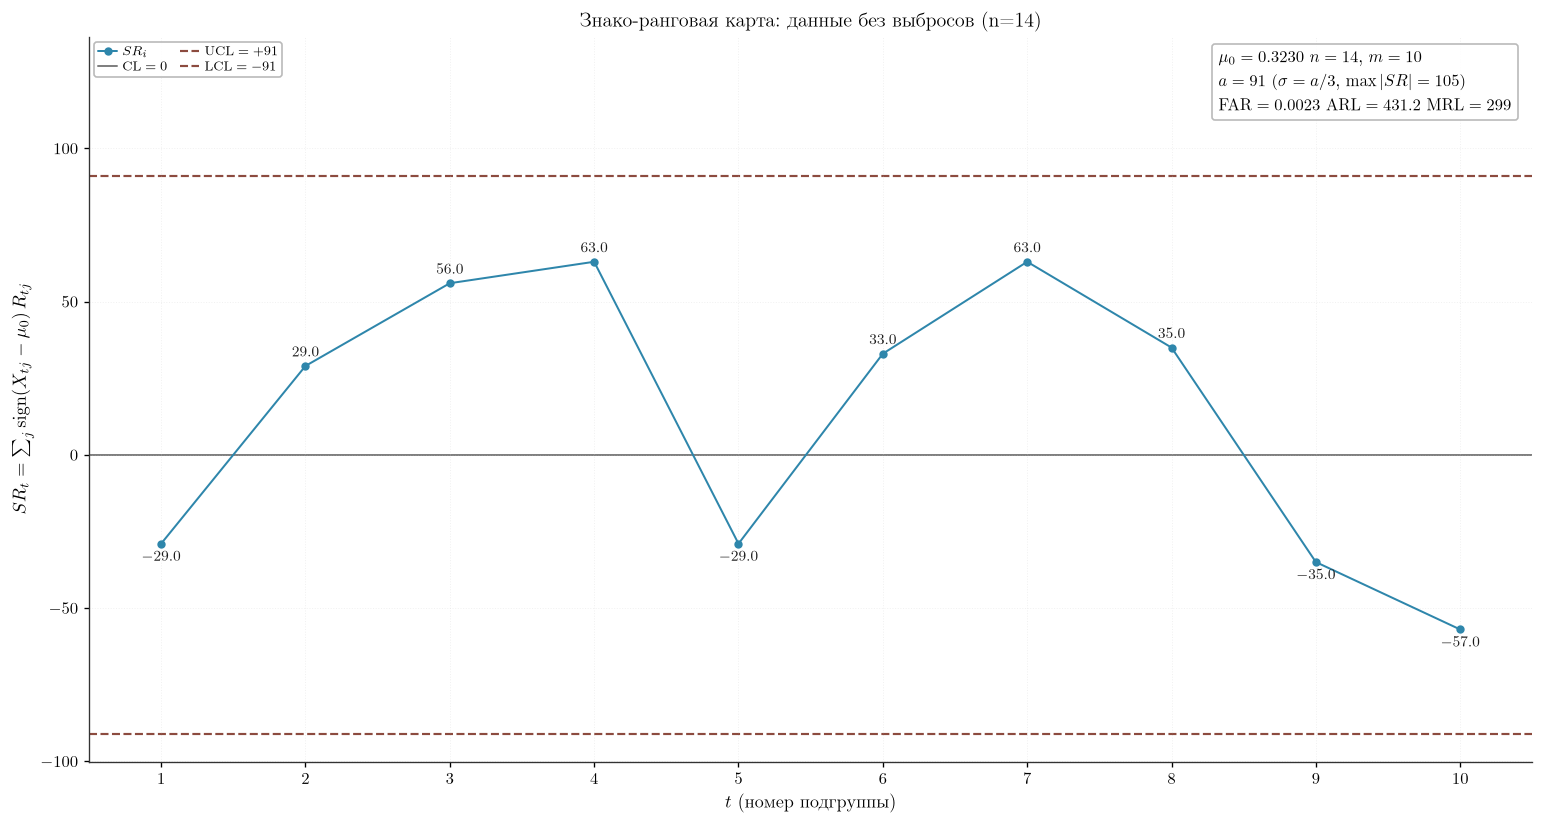

Сигналов: 0


,subgroup,value,rule


In [17]:
chart_clean = SignedRankChart(data_clean, sample_size=n, target_value=MU0,
                              approach='exact', far0=FAR0)
limits_clean = chart_clean.calculate_limits()

print(f"a = {limits_clean['a_value']}, "
      f"FAR = {limits_clean['FAR']:.6f}, "
      f"ARL_IC = {limits_clean['ARL_IC']:.1f}")

fig, ax = chart_clean.plot(
    title=f'Знако-ранговая карта: данные без выбросов (n={n})'
)
plt.show()

violations_clean = pd.DataFrame(chart_clean.violations)
print(f'Сигналов: {len(violations_clean)}')
display(violations_clean if len(violations_clean)
        else pd.DataFrame(columns=['subgroup', 'value', 'rule']))

**Комментарий.** Сигналов нет. При замене медианой выброс $-1.892$ стал
бы положительным ($+0.688$) и создал сигнал в подгруппе 4; винзоризация
оставляет его на нижнем заборе $-0.63$, то есть по-прежнему ниже $\mu_0$.
Карта не «придумывает» сдвиг сама — это честнее, хотя SR-карта и теряет
часть чувствительности.

## 9. Сравнение и итог

In [18]:
rows = []
for name, frame in [('исходные', data), ('без выбросов', data_clean)]:
    current = SignedRankChart(frame, sample_size=n, target_value=MU0,
                              approach='exact', far0=FAR0)
    current_limits = current.calculate_limits()
    rows.append({
        'вариант': name,
        'асимметрия': summarize_dataset(frame)['асимметрия'],
        'a': current_limits['a_value'],
        'FAR': current_limits['FAR'],
        'ARL_IC': current_limits['ARL_IC'],
        'MRL_IC': current_limits['MRL_IC'],
        'сигналов': len(current.violations),
        'подгруппы': ', '.join(
            str(item['subgroup']) for item in current.violations
        ) or '—',
    })

display(pd.DataFrame(rows).round(6))

,вариант,асимметрия,a,FAR,ARL_IC,MRL_IC,сигналов,подгруппы
0,исходные,10.366077,91,0.002319,431.157895,299,0,—
1,без выбросов,0.395729,91,0.002319,431.157895,299,0,—


**Выводы.**

1. SR-карта distribution-free только для непрерывных **симметричных**
   распределений; при асимметрии её выводы недействительны.
2. При $n=14$ точный подход даёт $a=91$ и достигнутый
   $FAR\approx 0.0023 \le FAR_0$; «ближайший» подход даёт FAR около $0.05$.
3. Выбросы искажают и асимметрию, и ранги: после винзоризации шести
   значений скос упал с $10.4$ до $0.40$; сигналов не появилось — очистка
   не создала искусственного сдвига.
4. Порядок работы: проверка данных (включая симметрию) → выбор параметров →
   карта; очистка данных — отдельный проход для сравнения.